# Analisis Sentimen Ulasan Aplikasi blu by BCA 

In [1]:
!pip -q install PySastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 16.4 MB/s eta 0:00:00


In [2]:
import re, os, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 1. Validasi & Cleaning Data

In [ ]:
DATA_PATH = 'dataset_ulasan_blubca.csv'
df_raw = pd.read_csv(DATA_PATH)
print('Shape awal  :', df_raw.shape)
print('Kolom       :', list(df_raw.columns))
print('Missing     :\n', df_raw.isna().sum())
print('Duplikat    :', df_raw.duplicated(subset='ulasan').sum())
print('\nDistribusi rating asli (kolom label):')
print(df_raw['label'].value_counts().sort_index())
df_raw.head()

Shape awal  : (12000, 2)
Kolom       : ['ulasan', 'label']
Missing     :
 ulasan    0
label     0
dtype: int64
Duplikat    : 15

Distribusi rating asli (kolom label):
label
1    3887
2    1019
3    1217
4    1064
5    4813
Name: count, dtype: int64


,ulasan,label
0,"Mohon diperbaiki, iklan poster eventnya sangat...",2
1,"mau log in aja muter lama banget, bilang sambu...",1
2,aplikasi blu kalau keluar dan login kembali fi...,1
3,"terlalu berbelit-belit, konfirmasi nya harus V...",1
4,"Hei blu, ini saya ada gangguan di hp mengakiba...",3


In [ ]:
df = df_raw.copy()
df = df.dropna(subset=['ulasan'])
df['ulasan'] = df['ulasan'].astype(str).str.strip()
df = df[df['ulasan'].str.len() >= 3]
df = df.drop_duplicates(subset='ulasan').reset_index(drop=True)
df = df.rename(columns={'label': 'rating'})
df = df[df['rating'].between(1, 5)]
print('Shape setelah cleaning:', df.shape)
assert len(df) >= 10000, 'Data kurang dari 10.000 sampel!'

Shape setelah cleaning: (11985, 2)


## 2. Labeling (Negatif / Netral / Positif)

In [ ]:
SLANG = {
 'gak':'tidak','ga':'tidak','nggak':'tidak','ngga':'tidak','enggak':'tidak','tdk':'tidak','gk':'tidak','gabisa':'tidak bisa','gaada':'tidak ada',
 'yg':'yang','dgn':'dengan','dg':'dengan','utk':'untuk','untk':'untuk','sy':'saya','aq':'saya','gw':'saya','gue':'saya','sya':'saya',
 'krn':'karena','karna':'karena','tp':'tapi','tpi':'tapi','jd':'jadi','jg':'juga','jga':'juga','udh':'sudah','udah':'sudah','sdh':'sudah',
 'blm':'belum','bgt':'banget','bgtt':'banget','banget':'sekali','skrg':'sekarang','sm':'sama','dr':'dari','pd':'pada','trs':'terus','terus2':'terus',
 'lg':'lagi','lgi':'lagi','org':'orang','hp':'handphone','apk':'aplikasi','app':'aplikasi','apps':'aplikasi','aplikasinya':'aplikasi','tf':'transfer',
 'trf':'transfer','pake':'pakai','pk':'pakai','kok':'kenapa','knp':'kenapa','kenapa2':'kenapa','mhn':'mohon','plis':'tolong','pls':'tolong',
 'tlg':'tolong','bkn':'bukan','byk':'banyak','jgn':'jangan','emg':'memang','emang':'memang','bs':'bisa','bsa':'bisa','lemot':'lambat','lelet':'lambat',
 'ribet':'rumit','mantap':'bagus','mantul':'bagus','keren':'bagus','oke':'baik','ok':'baik','good':'bagus','bagu':'bagus','sip':'baik',
 'thanks':'terima kasih','thx':'terima kasih','makasih':'terima kasih','trims':'terima kasih','error':'galat','eror':'galat','bug':'galat',
 'login':'masuk','log':'masuk','loading':'memuat','update':'perbarui','upgrade':'perbarui','ngelag':'lambat','lag':'lambat','crash':'galat',
}
NEGATIONS = {'tidak','bukan','belum','jangan'}

def normalize(text):
    t = str(text).lower()
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'@\w+|#\w+', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    t = re.sub(r'(.)\1{2,}', r'\1', t)
    out = []
    for tok in t.split():
        out.extend(SLANG.get(tok, tok).split())
    return out

In [ ]:

DOMAIN_POS = {'bagus':3,'baik':2,'mudah':2,'cepat':2,'lancar':3,'puas':3,'senang':3,'suka':2,'membantu':2,'bantu':2,'terbantu':2,'praktis':2,
 'aman':2,'nyaman':2,'lengkap':2,'terbaik':3,'rekomendasi':2,'direkomendasikan':2,'simpel':2,'simple':2,'sukses':2,'berhasil':2,'sempurna':3,
 'memuaskan':3,'cocok':2,'enak':2,'ramah':2,'responsif':2,'stabil':2,'andal':2,'handal':2,'lega':2,'hebat':3,'ringan':1,'manfaat':2,'bermanfaat':2,
 'murah':1,'gratis':1,'untung':1,'cashback':1,'promo':1,'terpercaya':2,'percaya':1,'canggih':2,'modern':1,'menarik':2,'rapi':2,'jelas':1,
 'efisien':2,'mantap':3,'keren':3,'top':2,'worth':2,'bersyukur':2,'terimakasih':1,'lumayan':1}
DOMAIN_NEG = {'lambat':3,'susah':3,'rumit':3,'gagal':3,'kecewa':4,'galat':3,'parah':4,'buruk':4,'jelek':4,'payah':4,'sulit':3,'lama':2,'berat':2,'macet':3,
 'hilang':3,'ditolak':3,'tolak':2,'masalah':2,'bermasalah':2,'keluhan':2,'tipu':4,'penipu':4,'penipuan':4,'scam':4,'rugi':3,'mahal':2,'blokir':3,
 'diblokir':3,'terblokir':3,'putus':2,'terputus':2,'mengecewakan':4,'menyebalkan':4,'kesal':3,'marah':3,'bingung':2,'mengganggu':3,'gangguan':3,
 'hang':3,'kurang':2,'uninstal':3,'pending':2,'komplain':2,'terpaksa':2,'sampah':4,'zonk':4,'pusing':2,'capek':2,'lelah':2,'sedih':2,
 'kesulitan':3,'kendala':2,'terkendala':2,'trouble':2,'maintenance':1,'perbaiki':1,'diperbaiki':1,'perbaikan':1,'mati':2,'kena':1,'potongan':1,
 'biaya':1,'denda':2,'tertahan':2,'tersendat':2,'tertunda':2,'bohong':4,'ribet':3,'muter':2,'berputar':2,'stuck':3}
DOMAIN = {**DOMAIN_POS, **{k: -v for k, v in DOMAIN_NEG.items()}}
PHRASES = {('tidak','bisa'):-3, ('tidak','dapat'):-3, ('tidak','ada'):-1, ('tidak','muncul'):-2,
           ('tidak','masuk'):-2, ('tidak','terima'):-2, ('tidak','respon'):-2}
PHRASE_WORDS = {b for (_, b) in PHRASES}

USE_INSET = False
LEXICON = dict(DOMAIN)
if USE_INSET:
    import urllib.request
    from collections import defaultdict
    base = 'https://raw.githubusercontent.com/fajri91/InSet/master/'
    def load_inset(fname):
        raw = urllib.request.urlopen(base + fname).read().decode('utf-8')
        d = {}
        for line in raw.splitlines()[1:]:
            p = line.split(chr(9))
            if len(p) >= 2:
                try: d[p[0].strip().lower()] = int(p[1])
                except ValueError: pass
        return d
    pos_lex, neg_lex = load_inset('positive.tsv'), load_inset('negative.tsv')
    inset = {w: v for w, v in {**pos_lex, **neg_lex}.items() if not (w in pos_lex and w in neg_lex)}
    idx = defaultdict(list)
    for i, s_ in enumerate(df['ulasan']):
        for t_ in set(normalize(s_)): idx[t_].append(i)
    ratings = df['rating'].values; gmean = ratings.mean()
    kept = {}
    for w, v in inset.items():
        ids = idx.get(w, [])
        if len(ids) < 15: continue
        m = ratings[ids].mean()
        if (v > 0 and m > gmean) or (v < 0 and m < gmean): kept[w] = v
    LEXICON = {**kept, **DOMAIN}
print('Ukuran leksikon:', len(LEXICON))
print({w: LEXICON.get(w) for w in ['bagus','baik','puas','lancar','cepat','mudah','kecewa','lambat','susah','gagal']})
assert LEXICON['bagus'] > 0 and LEXICON['lambat'] < 0 and LEXICON['kecewa'] < 0, 'Polaritas leksikon salah!'

Ukuran leksikon: 127
{'bagus': 3, 'baik': 2, 'puas': 3, 'lancar': 3, 'cepat': 2, 'mudah': 2, 'kecewa': -4, 'lambat': -3, 'susah': -3, 'gagal': -3}


In [7]:
def lexicon_score(tokens):
    score, i = 0, 0
    while i < len(tokens):
        if i + 1 < len(tokens) and (tokens[i], tokens[i+1]) in PHRASES:
            score += PHRASES[(tokens[i], tokens[i+1])]; i += 2; continue
        w = LEXICON.get(tokens[i])
        if w:
            if i > 0 and tokens[i-1] in NEGATIONS: w = -w   # negasi membalik polaritas
            score += w
        i += 1
    return score

def to_label(score):
    return 'positif' if score > 0 else ('negatif' if score < 0 else 'netral')

df['skor'] = df['ulasan'].map(lambda s: lexicon_score(normalize(s)))
df['sentimen'] = df['skor'].map(to_label)
dist = df['sentimen'].value_counts(normalize=True).round(3)
print(dist)
print('Baseline tebak kelas mayoritas:', dist.max())
assert dist.min() > 0.05 and dist.max() < 0.75, 'Distribusi kelas terlalu timpang - periksa leksikon!'
print('Validasi label vs rating asli (proporsi per baris):')
display(pd.crosstab(df['rating'], df['sentimen'], normalize='index').round(2))
df[['ulasan','rating','skor','sentimen']].sample(8, random_state=SEED)

sentimen
negatif    0.482
positif    0.374
netral     0.143
Name: proportion, dtype: float64
Baseline tebak kelas mayoritas: 0.482
Validasi label vs rating asli (proporsi per baris):


sentimen,negatif,netral,positif
rating,,,
1,0.79,0.14,0.07
2,0.75,0.15,0.10
3,0.66,0.18,0.16
4,0.43,0.18,0.39
5,0.14,0.13,0.73


,ulasan,rating,skor,sentimen
1470,"Aplikasi Bank Digital terburuk yang aku tau, a...",3,1,positif
10949,Blu terhenti terus.gak bisa login,1,-3,negatif
5566,aku kasih 1 dulu ya karena penilaian bca kepad...,1,0,netral
7510,"Lemot bangetttt,simpel aja dong jangan banyak ...",5,-1,negatif
554,Kadang login masuk gagal terus. Kalau gini aca...,2,-12,negatif
10906,"bagus,walau fiture nya sedikit ngelag",5,0,netral
2473,"aplikasi sampah, verikasi foto tidak bisa di k...",1,-13,negatif
932,"Transfer pakai biFast sudah bisa. Please min, ...",4,-2,negatif


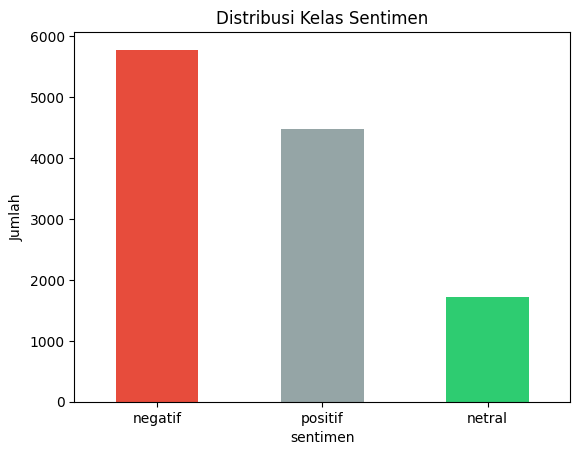

In [8]:
df['sentimen'].value_counts().plot(kind='bar', color=['#e74c3c','#95a5a6','#2ecc71'], title='Distribusi Kelas Sentimen')
plt.ylabel('Jumlah'); plt.xticks(rotation=0); plt.show()
assert df['sentimen'].nunique() == 3, 'Harus ada 3 kelas'

## 3. Preprocessing

In [9]:
STOPWORDS = set('''yang di ke dari dan atau untuk dengan pada ini itu adalah ada juga sudah akan saya kamu anda kita kami mereka nya lah kah pun
oleh agar supaya dalam sebagai seperti jadi karena sama kalau jika bila saat ketika lalu terus sih deh dong nih tuh ya yaa aja saja hanya
mau bisa apa siapa bagaimana kapan dimana mohon tolong terima kasih halo hai min admin kak'''.split())
stemmer = StemmerFactory().create_stemmer()
_stem_cache = {}
def stem_word(w):
    if w not in _stem_cache: _stem_cache[w] = stemmer.stem(w)
    return _stem_cache[w]

USE_STEMMING = False
FOCUS_INPUT = True
KEEP_TOKENS = set(LEXICON) | NEGATIONS | PHRASE_WORDS

def focus_tokens(toks):
    out, gap_added = [], False
    for i, t in enumerate(toks):
        if t in KEEP_TOKENS:
            out.append(t); gap_added = False
        elif out and out[-1] in NEGATIONS and not gap_added and i > 0 and toks[i-1] == out[-1]:
            out.append('sela'); gap_added = True
    return ' '.join(out) if out else 'kosong'

def preprocess(text):
    toks = normalize(text)
    if FOCUS_INPUT:
        return focus_tokens(toks)
    kept = []
    for t in toks:
        if t in KEEP_TOKENS:
            kept.append(t)
        elif t not in STOPWORDS and len(t) > 1:
            kept.append(stem_word(t) if USE_STEMMING else t)
    return ' '.join(kept)

df['clean'] = df['ulasan'].map(preprocess)
df = df[df['clean'].str.strip().str.len() > 0].reset_index(drop=True)
print('Jumlah data akhir:', len(df))
df[['ulasan','clean','sentimen']].head(5)

Jumlah data akhir: 11985


,ulasan,clean,sentimen
0,"Mohon diperbaiki, iklan poster eventnya sangat...",diperbaiki mengganggu lambat lambat aman diper...,negatif
1,"mau log in aja muter lama banget, bilang sambu...",masuk muter lama putus baik tidak bisa masuk b...,negatif
2,aplikasi blu kalau keluar dan login kembali fi...,masuk sulit jelas tidak sela gagal masuk stabi...,negatif
3,"terlalu berbelit-belit, konfirmasi nya harus V...",tidak masalah ada susah bisa,negatif
4,"Hei blu, ini saya ada gangguan di hp mengakiba...",ada gangguan tidak ada masuk trouble bisa masuk,negatif


## 4. Train / Validation / Test Split (stratified)

In [10]:
le = LabelEncoder()
y_all = le.fit_transform(df['sentimen'])          # urutan alfabet: negatif=0, netral=1, positif=2
CLASS_NAMES = list(le.classes_)
print('Kelas:', CLASS_NAMES)

def split_data(X, y, train=0.8, val=0.1, test=0.1):
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=(1-train), stratify=y, random_state=SEED)
    rel_test = test / (val + test)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=rel_test, stratify=y_tmp, random_state=SEED)
    return X_tr, X_va, X_te, y_tr, y_va, y_te

texts = df['clean'].values

Kelas: ['negatif', 'netral', 'positif']


## 5. Feature Extraction & Fungsi Training/Evaluasi

In [11]:
def seq_features(X_tr, X_va, X_te, num_words=None):
    tok = Tokenizer(num_words=num_words, oov_token='<OOV>')
    tok.fit_on_texts(X_tr)
    maxlen = int(np.percentile([len(s.split()) for s in X_tr], 95))
    f = lambda X: pad_sequences(tok.texts_to_sequences(X), maxlen=maxlen, padding='post', truncating='post')
    return f(X_tr), f(X_va), f(X_te), tok, maxlen

results = {}      # ringkasan tiap skema
predictors = {}   # fungsi inference tiap skema

def train_and_eval(name, model, Xtr, ytr, Xva, yva, Xte, yte, epochs=40, batch_size=64, use_cw=False):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cw = dict(enumerate(compute_class_weight('balanced', classes=np.unique(ytr), y=ytr))) if use_cw else None
    es = callbacks.EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True)
    rl = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=0)
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=batch_size,
                     class_weight=cw, callbacks=[es, rl], verbose=2)
    tr_acc = accuracy_score(ytr, model.predict(Xtr, verbose=0).argmax(1))
    va_acc = accuracy_score(yva, model.predict(Xva, verbose=0).argmax(1))
    pred_te = model.predict(Xte, verbose=0).argmax(1)
    te_acc = accuracy_score(yte, pred_te)
    print(f'\n[{name}] Train acc={tr_acc:.4f} | Val acc={va_acc:.4f} | Test acc={te_acc:.4f}')
    print(classification_report(yte, pred_te, target_names=CLASS_NAMES, digits=4))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(hist.history['accuracy'], label='train'); ax[0].plot(hist.history['val_accuracy'], label='val')
    ax[0].set_title(f'{name} - Accuracy'); ax[0].legend()
    ax[1].plot(hist.history['loss'], label='train'); ax[1].plot(hist.history['val_loss'], label='val')
    ax[1].set_title(f'{name} - Loss'); ax[1].legend()
    sns.heatmap(confusion_matrix(yte, pred_te), annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[2])
    ax[2].set_title('Confusion Matrix (Test)'); ax[2].set_xlabel('Prediksi'); ax[2].set_ylabel('Aktual')
    plt.tight_layout(); plt.show()
    results[name] = dict(train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc, f1=f1_score(yte, pred_te, average='macro'), model=model)
    return model

## 6. Skema 1 — Bidirectional LSTM + Tokenizer/Embedding (split 80/10/10)

Split 80/10/10 -> 9588 1198 1199


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 9, 128)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 9, 128)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,675 (487.01 KB)

 Trainable params: 124,675 (487.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
150/150 - 16s - 107ms/step - accuracy: 0.8144 - loss: 0.4818 - val_accuracy: 0.9190 - val_loss: 0.2360 - learning_rate: 0.0010
Epoch 2/40
150/150 - 2s - 12ms/step - accuracy: 0.9247 - loss: 0.2216 - val_accuracy: 0.9324 - val_loss: 0.1874 - learning_rate: 0.0010
Epoch 3/40
150/150 - 2s - 15ms/step - accuracy: 0.9376 - loss: 0.1888 - val_accuracy: 0.9307 - val_loss: 0.1826 - learning_rate: 0.0010
Epoch 4/40
150/150 - 1s - 9ms/step - accuracy: 0.9421 - loss: 0.1719 - val_accuracy: 0.9416 - val_loss: 0.1578 - learning_rate: 0.0010
Epoch 5/40
150/150 - 1s - 9ms/step - accuracy: 0.9491 - loss: 0.1538 - val_accuracy: 0.9491 - val_loss: 0.1495 - learning_rate: 0.0010
Epoch 6/40
150/150 - 1s - 9ms/step - accuracy: 0.9521 - loss: 0.1458 - val_accuracy: 0.9524 - val_loss: 0.1369 - learning_rate: 0.0010
Epoch 7/40
150/150 - 1s - 9ms/step - accuracy: 0.9576 - loss: 0.1275 - val_accuracy: 0.9549 - val_loss: 0.1361 - learning_rate: 0.0010
Epoch 8/40
150/150 - 1s - 10ms/step - accuracy: 0.

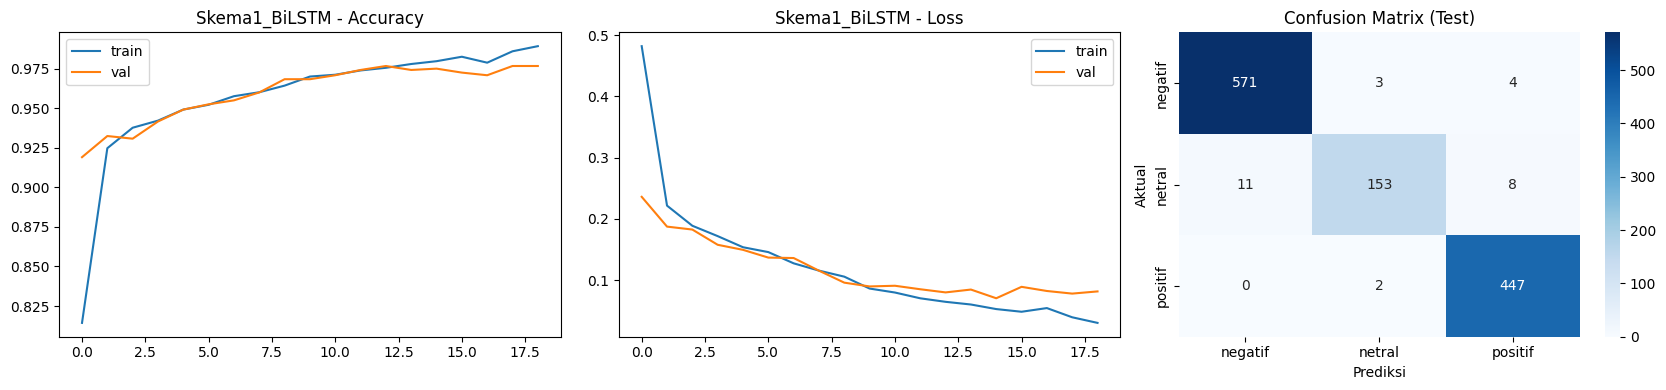

In [12]:
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(texts, y_all, 0.8, 0.1, 0.1)
print('Split 80/10/10 ->', len(X_tr), len(X_va), len(X_te))
Str, Sva, Ste, tok1, maxlen1 = seq_features(X_tr, X_va, X_te)
vocab1 = len(tok1.word_index) + 1

m1 = models.Sequential([
    layers.Input(shape=(maxlen1,)),
    layers.Embedding(vocab1, 128),
    layers.SpatialDropout1D(0.2),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')])
m1.summary()
m1 = train_and_eval('Skema1_BiLSTM', m1, Str, y_tr, Sva, y_va, Ste, y_te)

def make_seq_predictor(model, tok, maxlen):
    def predict(text):
        x = pad_sequences(tok.texts_to_sequences([preprocess(text)]), maxlen=maxlen, padding='post', truncating='post')
        p = model.predict(x, verbose=0)[0]
        return CLASS_NAMES[int(p.argmax())], p
    return predict
predictors['Skema1_BiLSTM'] = make_seq_predictor(m1, tok1, maxlen1)

## 7. Skema 2 — CNN 1D + Tokenizer/Embedding (split 70/15/15)

Split 70/15/15 -> 8389 1798 1798


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 9, 128)         │        17,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 9, 128)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 5, 128)         │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,779 (421.01 KB)

 Trainable params: 107,779 (421.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
132/132 - 11s - 84ms/step - accuracy: 0.7748 - loss: 0.5800 - val_accuracy: 0.9232 - val_loss: 0.2796 - learning_rate: 0.0010
Epoch 2/40
132/132 - 1s - 4ms/step - accuracy: 0.9131 - loss: 0.2784 - val_accuracy: 0.9360 - val_loss: 0.1962 - learning_rate: 0.0010
Epoch 3/40
132/132 - 1s - 4ms/step - accuracy: 0.9248 - loss: 0.2221 - val_accuracy: 0.9366 - val_loss: 0.1749 - learning_rate: 0.0010
Epoch 4/40
132/132 - 1s - 4ms/step - accuracy: 0.9324 - loss: 0.1980 - val_accuracy: 0.9422 - val_loss: 0.1694 - learning_rate: 0.0010
Epoch 5/40
132/132 - 1s - 4ms/step - accuracy: 0.9348 - loss: 0.1820 - val_accuracy: 0.9472 - val_loss: 0.1553 - learning_rate: 0.0010
Epoch 6/40
132/132 - 1s - 4ms/step - accuracy: 0.9397 - loss: 0.1679 - val_accuracy: 0.9533 - val_loss: 0.1409 - learning_rate: 0.0010
Epoch 7/40
132/132 - 1s - 4ms/step - accuracy: 0.9450 - loss: 0.1508 - val_accuracy: 0.9544 - val_loss: 0.1343 - learning_rate: 0.0010
Epoch 8/40
132/132 - 1s - 4ms/step - accuracy: 0.9486

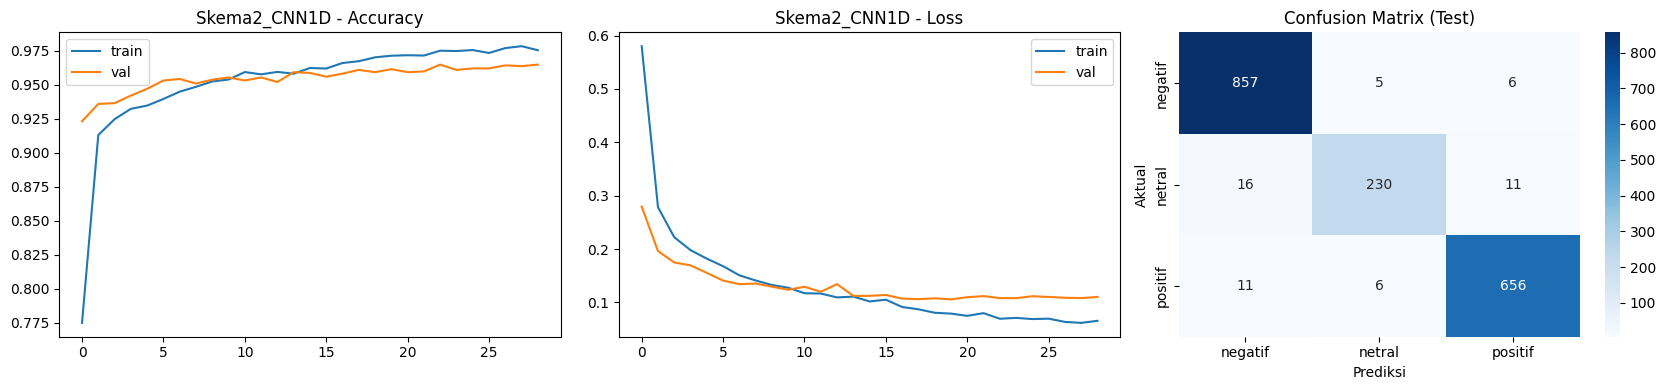

In [13]:
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(texts, y_all, 0.7, 0.15, 0.15)
print('Split 70/15/15 ->', len(X_tr), len(X_va), len(X_te))
Str, Sva, Ste, tok2, maxlen2 = seq_features(X_tr, X_va, X_te)
vocab2 = len(tok2.word_index) + 1

m2 = models.Sequential([
    layers.Input(shape=(maxlen2,)),
    layers.Embedding(vocab2, 128),
    layers.SpatialDropout1D(0.3),
    layers.Conv1D(128, 5, activation='relu'),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')])
m2.summary()
m2 = train_and_eval('Skema2_CNN1D', m2, Str, y_tr, Sva, y_va, Ste, y_te)
predictors['Skema2_CNN1D'] = make_seq_predictor(m2, tok2, maxlen2)

## 8. Skema 3 — MLP + TF-IDF unigram+bigram (split 80/10/10)

TF-IDF shape: (9588, 2121)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │       543,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 559,875 (2.14 MB)

 Trainable params: 559,875 (2.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
150/150 - 7s - 50ms/step - accuracy: 0.7826 - loss: 0.5445 - val_accuracy: 0.9466 - val_loss: 0.1907 - learning_rate: 0.0010
Epoch 2/40
150/150 - 1s - 4ms/step - accuracy: 0.9419 - loss: 0.1756 - val_accuracy: 0.9541 - val_loss: 0.1367 - learning_rate: 0.0010
Epoch 3/40
150/150 - 1s - 4ms/step - accuracy: 0.9638 - loss: 0.1125 - val_accuracy: 0.9583 - val_loss: 0.1239 - learning_rate: 0.0010
Epoch 4/40
150/150 - 1s - 4ms/step - accuracy: 0.9756 - loss: 0.0732 - val_accuracy: 0.9566 - val_loss: 0.1188 - learning_rate: 0.0010
Epoch 5/40
150/150 - 1s - 4ms/step - accuracy: 0.9837 - loss: 0.0536 - val_accuracy: 0.9583 - val_loss: 0.1234 - learning_rate: 0.0010
Epoch 6/40
150/150 - 1s - 4ms/step - accuracy: 0.9878 - loss: 0.0387 - val_accuracy: 0.9616 - val_loss: 0.1313 - learning_rate: 0.0010
Epoch 7/40
150/150 - 1s - 4ms/step - accuracy: 0.9920 - loss: 0.0287 - val_accuracy: 0.9608 - val_loss: 0.1327 - learning_rate: 5.0000e-04
Epoch 8/40
150/150 - 1s - 4ms/step - accuracy: 0.9

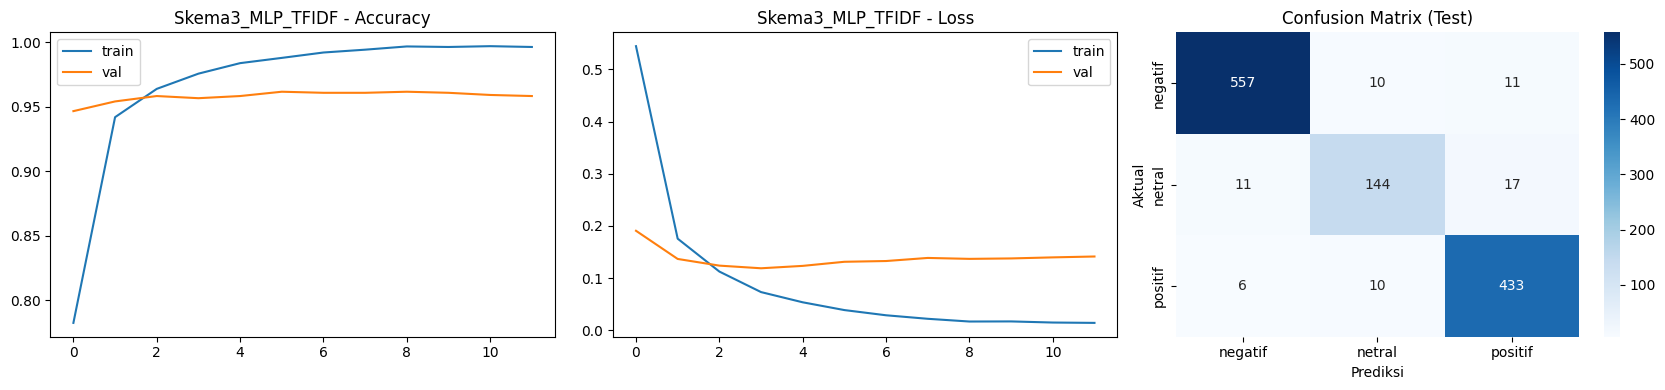

In [14]:
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(texts, y_all, 0.8, 0.1, 0.1)
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Ttr = tfidf.fit_transform(X_tr).toarray().astype('float32')
Tva = tfidf.transform(X_va).toarray().astype('float32')
Tte = tfidf.transform(X_te).toarray().astype('float32')
print('TF-IDF shape:', Ttr.shape)

m3 = models.Sequential([
    layers.Input(shape=(Ttr.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')])
m3.summary()
m3 = train_and_eval('Skema3_MLP_TFIDF', m3, Ttr, y_tr, Tva, y_va, Tte, y_te)

def tfidf_predict(text):
    p = m3.predict(tfidf.transform([preprocess(text)]).toarray().astype('float32'), verbose=0)[0]
    return CLASS_NAMES[int(p.argmax())], p
predictors['Skema3_MLP_TFIDF'] = tfidf_predict

## 9. Perbandingan Evaluasi Ketiga Skema

In [15]:
summary = pd.DataFrame([
    {'Skema': k, 'Train Acc': v['train_acc'], 'Val Acc': v['val_acc'], 'Test Acc': v['test_acc'], 'Test Macro-F1': v['f1'],
     'Train>92%': v['train_acc'] > 0.92, 'Test>92%': v['test_acc'] > 0.92}
    for k, v in results.items()])
summary['Algoritma'] = ['BiLSTM', 'CNN 1D', 'MLP']
summary['Fitur'] = ['Tokenizer+Embedding', 'Tokenizer+Embedding', 'TF-IDF (1,2)-gram']
summary['Split'] = ['80/10/10', '70/15/15', '80/10/10']
summary = summary[['Skema','Algoritma','Fitur','Split','Train Acc','Val Acc','Test Acc','Test Macro-F1','Train>92%','Test>92%']]
display(summary.style.format({'Train Acc':'{:.4f}','Val Acc':'{:.4f}','Test Acc':'{:.4f}','Test Macro-F1':'{:.4f}'}))
best_name = max(results, key=lambda k: results[k]['test_acc'])
print('Skema terbaik (test acc):', best_name)

,Skema,Algoritma,Fitur,Split,Train Acc,Val Acc,Test Acc,Test Macro-F1,Train>92%,Test>92%
0,Skema1_BiLSTM,BiLSTM,Tokenizer+Embedding,80/10/10,0.9838,0.9766,0.9766,0.9654,True,True
1,Skema2_CNN1D,CNN 1D,Tokenizer+Embedding,70/15/15,0.9918,0.9650,0.9694,0.9589,True,True
2,Skema3_MLP_TFIDF,MLP,"TF-IDF (1,2)-gram",80/10/10,0.9968,0.9616,0.9458,0.9253,True,True


Skema terbaik (test acc): Skema1_BiLSTM


## 10. Simpan Model Terbaik

In [16]:
os.makedirs('artifacts', exist_ok=True)
results[best_name]['model'].save(f'artifacts/{best_name}.keras')
with open('artifacts/tokenizer_skema1.pkl', 'wb') as f: pickle.dump((tok1, maxlen1), f)
with open('artifacts/tokenizer_skema2.pkl', 'wb') as f: pickle.dump((tok2, maxlen2), f)
with open('artifacts/tfidf_skema3.pkl', 'wb') as f: pickle.dump(tfidf, f)
with open('artifacts/class_names.pkl', 'wb') as f: pickle.dump(CLASS_NAMES, f)
print('Tersimpan di folder artifacts/')

Tersimpan di folder artifacts/


## 11. Inference

In [17]:
contoh = [
    'Aplikasinya bagus banget, transfer cepat dan fiturnya lengkap. Sangat membantu!',
    'Parah, login susah terus, aplikasi lambat dan sering error. Kecewa sekali.',
    'Saya baru mencoba aplikasi ini untuk membuka rekening tabungan.',
    'Tampilan oke tapi sering gagal masuk, tolong diperbaiki.',
    'Mantap, promo banyak dan pembayaran QRIS lancar.',
    'Tidak bagus, verifikasi wajah selalu gagal.',
]
rows = []
for t in contoh:
    row = {'Ulasan': t}
    for name, fn in predictors.items():
        label, prob = fn(t)
        row[name] = label
    rows.append(row)
inference_df = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 80)
display(inference_df)

,Ulasan,Skema1_BiLSTM,Skema2_CNN1D,Skema3_MLP_TFIDF
0,"Aplikasinya bagus banget, transfer cepat dan fiturnya lengkap. Sangat membantu!",positif,positif,positif
1,"Parah, login susah terus, aplikasi lambat dan sering error. Kecewa sekali.",negatif,negatif,negatif
2,Saya baru mencoba aplikasi ini untuk membuka rekening tabungan.,netral,netral,netral
3,"Tampilan oke tapi sering gagal masuk, tolong diperbaiki.",negatif,negatif,negatif
4,"Mantap, promo banyak dan pembayaran QRIS lancar.",positif,positif,positif
5,"Tidak bagus, verifikasi wajah selalu gagal.",negatif,negatif,negatif


In [18]:
# Inference
def predict_sentiment(text, scheme=None):
    fn = predictors[scheme or best_name]
    label, prob = fn(text)
    return label, {c: round(float(p), 4) for c, p in zip(CLASS_NAMES, prob)}

for t in contoh[:3]:
    print(f'Ulasan : {t}')
    print('Hasil  :', predict_sentiment(t), '\n')

Ulasan : Aplikasinya bagus banget, transfer cepat dan fiturnya lengkap. Sangat membantu!
Hasil  : ('positif', {'negatif': 0.0, 'netral': 0.0, 'positif': 1.0}) 

Ulasan : Parah, login susah terus, aplikasi lambat dan sering error. Kecewa sekali.
Hasil  : ('negatif', {'negatif': 1.0, 'netral': 0.0, 'positif': 0.0}) 

Ulasan : Saya baru mencoba aplikasi ini untuk membuka rekening tabungan.
Hasil  : ('netral', {'negatif': 0.0, 'netral': 0.9999, 'positif': 0.0}) 

